# TP1. Classification de chiffres avec un perceptron multicouches

L'objectif de ce TP est d'entraîner un perceptron multicouches à classifier correctement des images de chiffres.
On utilisera le dataset MNIST pour l'entraînement et l'évaluation du modèle. On évaluera aussi le modèle lorsque les chiffres sont légèrement décalées.

**Important :** Avant de commencer ce tp, lisez attentivement la page "Classification MNIST" du cours.


In [1]:
import torch
import time
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

torch.manual_seed(0)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


<fieldset>
  <legend><b><font color="#dc3545" size="5"> ⚠️ WARNING</font></b></legend>
Si l'exécution de la cellule précédente affiche <code>cpu</code>, alors il faut modifier l'exécution pour faire tourner le notebook sur un GPU.
Pour cela, aller dans le menu "Exécution" -> "Modifier le type d'exécution" et choisir "GPU T4". Si vous réexécutez la cellule précédente, la sortie devrait être <code>cuda</code>.
</fieldset>

## Chargement du dataset MNIST et création des batchs


In [2]:
train_set = datasets.MNIST(root="data", download=True, transform=transforms.ToTensor())
test_set = datasets.MNIST(root="data", download=True, transform=transforms.ToTensor(), train=False)

batch_size = 256
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

print(len(train_set), "images d'entrainement /", len(test_set), "de test")
print("Forme d'une image :", train_set[0][0].shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.13MB/s]

60000 images d'entrainement / 10000 de test
Forme d'une image : torch.Size([1, 28, 28])


### Aperçu de quelques images

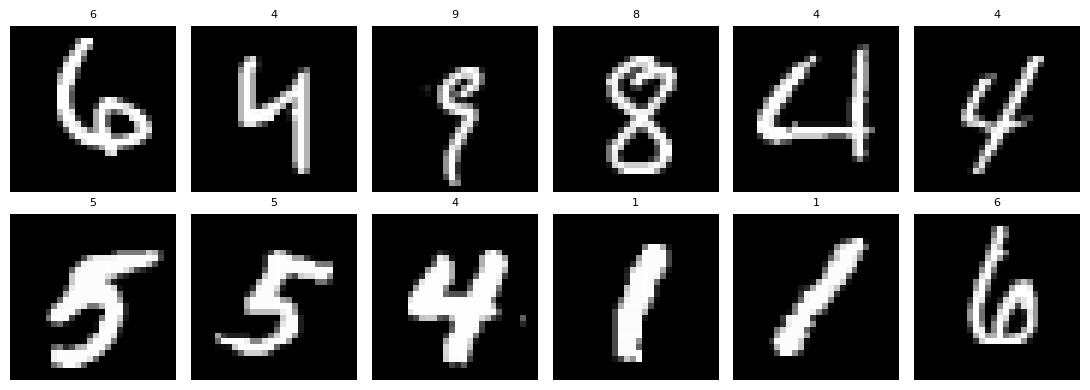

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.ravel(), np.random.choice(len(train_set), 12, replace=False)):
    img, lab = train_set[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## Évaluation et entraînement

Récupérez le code des fonctions `evaluer`et `entrainer` du cours et copiez-les ici.

In [13]:
##############################
#   Saisir votre code ici.   #
##############################


def evaluer(model, loader):
    """ Retourne la précision du modèle sur le dataset loader,
    c'est-à-dire nombre de bonnes prédictions / nombre prédictions"""
    correct = 0
    total = 0
    with torch.no_grad(): # pas de rétropropagation sur ces instructions
        for x, y in loader:
            x, y = x.to(device), y.to(device) # On envoie sur gpu
            scores = model(x) # Passe forward : on obtient les scores pour chaque chiffre
            pred = scores.argmax(dim=1) # retourne l'indice correspondant au score max, donc le chiffre prédit
                                        # Attention : on travaille par batch donc on a l'indice pour chaque élément
                                        # du batch
            correct += (pred == y).sum().item() # on compte le nombre de fois où la prédiction = label
            total += y.size(0) # taille du batch
    return correct / total



def entrainer(model, train_loader, epochs=10):
    """Boucle d'entraînement.
    Affiche la valeur de la loss d'entraînement à chaque itération.
    Affiche le temps d'entraînement à la fin.
    """
    model = model.to(device) # On met le modèle sur GPU
    opt = torch.optim.Adam(model.parameters()) # On utilise Adam pour l'optimisation
    loss_function = nn.CrossEntropyLoss(reduction="sum") # critère d'évaluation : loss utilisée

    t0 = time.time()
    # Pour chaque époque
    for ep in range(1, epochs + 1):
        somme, n = 0.0, 0

        # Pour chaque batch
        for x, y in train_loader:
            x, y = x.to(device), y.to(device) # copie du batch sur GPU (si dispo)
            opt.zero_grad() # on remet à 0 les gradients
            loss = loss_function(model(x), y) # on calcule la loss
            loss.backward() # on rétropropage
            opt.step() # on met à jour les paramètres de l'optimiseur
            somme += loss.item() # On calcule la loss sur le dataset entier
            n += y.size(0)
        print(f"epoque {ep:2d}/{epochs} - loss {somme/n:.4f}")

    duree = time.time() - t0
    print(f"Entraînement termine en {duree:.1f}s")



## Question : Perceptron multicouches


Définissez un perceptron multicouches. On supposera qu'il contient deux couches cachées de dimension respectives 256 et 128.

In [5]:
##############################
#   Saisir votre code ici.   #
##############################




## Question : nombre de paramètres

Combien de paramètres a ce réseau de neurones ?

**Réponse :** Écrire votre réponse ici.




## Entraînement

Entraînez votre modèle sur 10 époques. Quelle précision a-t-il ? Que se passe-t-il si on l'entraîne sur 20 époques ?

In [6]:
##############################
#   Saisir votre code ici.   #
##############################




## Classification d'images translatées

Le perceptron multicouches défini est très précis pour classer les images. Qu'en est-il si les images qu'il doit classer sont décalées verticalement et/ou horizontalement sans que le chiffre soit rogné ?

Pour cela, on propose d'évaluer la précision du même modèle, **sans le réentraîner**, sur le même dataset de test mais modifié de telle manière que les images soient décalées.
On donne le code pour créer, à partir du dataset de test, un deuxième dataset dans lequel les images sont décalées sans que les chiffres soient rognés.

In [7]:
from torch.utils.data import TensorDataset

def shift_images(images):
    """
    images    : tableau (N, H, W), fond noir = 0
                N : nombre d'images, H : hauteur, W : largeur
    max_shift : amplitude maximale du décalage en pixels (None = tout l'espace libre)
    Retourne un tableau de même forme avec chaque chiffre décalé aléatoirement,
    sans jamais rogner le chiffre.
    """
    rng = np.random.default_rng()
    images = np.asarray(images)
    out = np.empty_like(images)
    N, H, W = images.shape

    for i in range(N):
        img = images[i]
        rows = np.flatnonzero(img.max(axis=1) > 0)   # lignes contenant du chiffre
        cols = np.flatnonzero(img.max(axis=0) > 0)   # colonnes contenant du chiffre

        if len(rows) == 0:                            # image entièrement noire
            out[i] = img
            continue

        # décalages possibles pour que le chiffre reste dans l'image
        dy_min, dy_max = -rows[0], H - 1 - rows[-1]
        dx_min, dx_max = -cols[0], W - 1 - cols[-1]



        dy = rng.integers(dy_min, dy_max + 1)
        dx = rng.integers(dx_min, dx_max + 1)

        out[i] = np.roll(img, shift=(dy, dx), axis=(0, 1))

    return out

# On crée le dataset de test où les chiffres sont décalés sans être rognés
X = test_set.data.numpy()      # (10000, 28, 28), uint8
y = test_set.targets           # (10000,)
X_shifted = shift_images(X)
X_shifted = torch.from_numpy(X_shifted).float().div(255).unsqueeze(1)

shifted_set = TensorDataset(X_shifted, y)
shifted_loader = DataLoader(shifted_set, batch_size=batch_size, shuffle=False)

### Affichage de quelques images décalées

On affiche 12 images du dataset de test et les mêmes images décalées.

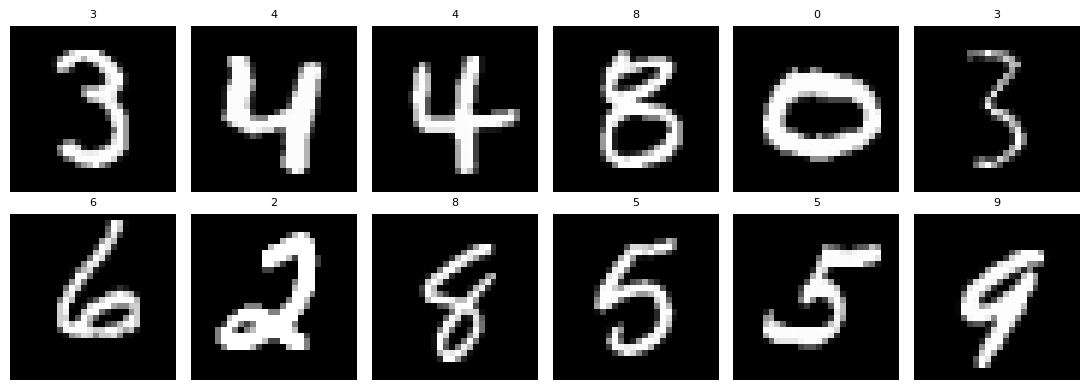

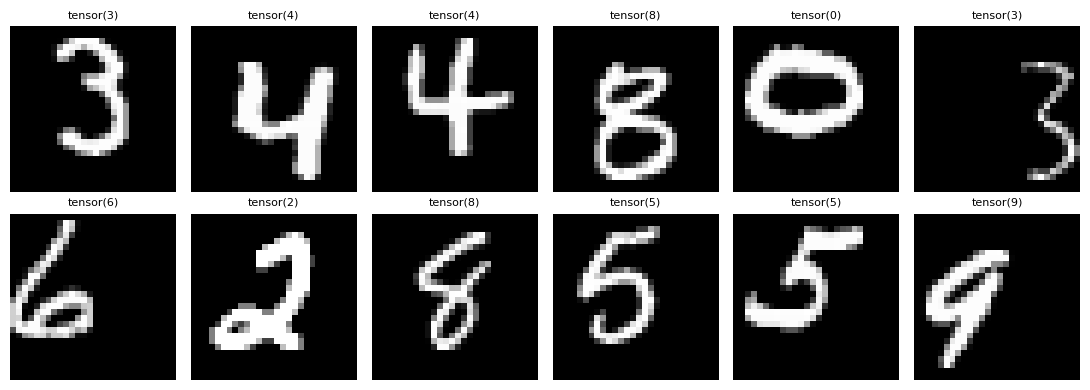

In [8]:
# Choix aléatoire d'images
alea = np.random.choice(len(test_set), 12, replace=False)

# Plot d'images du dataset de test
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.ravel(), alea):
    img, lab = test_set[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

#plot d'images du dataset modifié shifted_set
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.ravel(), alea):
    img, lab = shifted_set[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()



## Question : Évaluation du perceptron multicouches sur le dataset décalé

Évaluez la précision du modèle sur le dataset `shifted_loader`. Qu'est-ce qui se passe au niveau de la précision ? Que se passe-t-il si je double la dimension de chaque couche cachée ? Pourquoi ? Que peut-on conclure de la translation d'images pour un perceptron multicouches ?

In [9]:
##############################
#   Saisir votre code ici.   #
##############################




## Pour aller plus loin

Vous pouvez approfondir ce tp en répondant à ces différentes questions.

### Réaliser une tâche de classification plus difficile

Le dataset MNIST est relativement simple et presque tous les modèles d'apprentissage arrivent à donner de bons résultats.
Il peut être intéressant de travailler sur un dataset plus difficile. On peut par exemple entraîner et tester le modèle sur MNIST-1D ou Fashion-MNIST.

**Remarque :** Il existe évidemment bien d'autres datasets mais ils sont beaucoup plus grands. Cela nécessite beaucoup plus d'espace et de temps pour l'entraînement.

#### Dataset MNIST-1D

Ce dataset a été créé de manière à ce que la classification soit plus difficile mais que l'entraînement soit très rapide. C'est encore une classification de chiffre mais chaque entrée correspond à un vecteur de taille 40. Pour plus d'information, voir [ici](https://github.com/greydanus/mnist1d).

Pour l'utiliser, il faut d'abord l'installer avec la commande suivante :

In [10]:
!python -m pip install git+https://github.com/greydanus/mnist1d.git@master

  Cloning https://github.com/greydanus/mnist1d.git (to revision master) to /tmp/pip-req-build-idl8c14c
  Running command git clone --filter=blob:none --quiet https://github.com/greydanus/mnist1d.git /tmp/pip-req-build-idl8c14c
  Resolved https://github.com/greydanus/mnist1d.git to commit e2f536fa86442c13473b433d579e9852ec4d1c1d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for mnist1d: filename=mnist1d-0.0.2.post23-py3-none-any.whl size=14666 sha256=4ec167e48ded8c8570b74325fa3dfdf026ad1a6b38e55422af98d216e1126d6f
  Stored in directory: /tmp/pip-ephem-wheel-cache-r47db83x/wheels/c2/6a/67/3f21c6600a533f14e282d8e03c3fb08922f0ee05e0a2020799
Successfully built mnist1d


On peut ensuite générer un dataset de la manière suivante :

In [12]:
from mnist1d.data import get_dataset_args, get_dataset
args = get_dataset_args()
data = get_dataset(args, download=False, generate=True)

x_train = torch.tensor(data["x"], dtype=torch.float32)
y_train = torch.tensor(data["y"], dtype=torch.long)
x_test  = torch.tensor(data["x_test"], dtype=torch.float32)
y_test  = torch.tensor(data["y_test"], dtype=torch.long)

# Création des datasets
train_dataset = TensorDataset(x_train, y_train)
test_dataset  = TensorDataset(x_test, y_test)

Did or could not load data from ./mnist1d_data.pkl. Rebuilding dataset...


TypeError: make_dataset() got an unexpected keyword argument 'generate'

#### Dataset Fashion-MNIST

C'est un dataset constitué de petites images en noir et blanc représentant des vêtements, chaussures et sacs au même format que dans MNIST. Il faut déterminer ce que représente chaque image (10 classes possibles). Plus d'information [ici](https://github.com/zalandoresearch/fashion-mnist).

Il est possible d'utiliser le dataset de la manière suivante :

In [ ]:
train_set = torchvision.datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transforms.ToTensor())
test_set  = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

### Modifier les hyperparamètres

Il est possible de modifier les hyperparamètres de votre modèle : nombre de couches cachées et dimension de chaque couche. Cela change-t-il les performances sur les nouveaux datasets ?

### Tracer des courbes

Généralement, il est intéressant de visualiser l'évolution de certaines données durant l'entraînement. On peut vouloir tracer la courbe de la loss à chaque époque de l'entraînement. On peut aussi tracer la courbe de la précision du modèle sur le dataset d'entraînement et le dataset de test pour voir la corrélation entre la diminution de la loss et l'augmentation de la précision.

Pour tracer une courbe, on peut utiliser la librairie `matplotlib`. Voici un exemple d'utilisation :

In [ ]:
import matplotlib.pyplot as plt

# Fake data
epoques = np.array(range(50))
loss = np.random.rand(len(epoques))

# On trace la courbe : abscisse : époque, ordonnée : loss
plt.plot(loss, label="loss du train")
plt.xlabel("époque"); plt.ylabel("loss"); plt.legend()
plt.show()

Sur les différents datasets, la loss et la précision sur le dataset sont-ils corrélés ? Pourquoi ?